# Where do our conversions come from?
## A visual analysis of a bank's phone marketing campaigns

**Business question.** A marketing manager asks: *"Where do our conversions actually come from, and what should we change in the next campaign?"*

**Data.** 41,188 phone contacts made by a Portuguese retail bank between May 2008 and November 2010. Each row is the last call to one client in a campaign, and the column `y` says whether the client subscribed to a term deposit. Source: UCI Machine Learning Repository, "Bank Marketing" (Moro, Cortez and Rita, 2014), licence CC BY 4.0.

**How this notebook is organised.**

1. Setup and a small styling helper (so every chart looks the same)
2. Load and prepare the data
3. Ten questions. Each one follows the same pattern: **question -> chart -> takeaway**
4. A one-page summary figure

**A word on honesty.** This is observational data: nobody ran an experiment. The charts show *associations*, not causes. Several charts below exist precisely to show where a simple comparison would be misleading.

## 1. Setup

Import the libraries and define where the data and the images live. The paths are relative to this notebook (which sits in `notebooks/`), so the project runs on any computer.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import FuncFormatter, PercentFormatter

DATA = Path("..") / "data"      # raw data lives here
IMAGES = Path("..") / "images"  # every chart is saved here
IMAGES.mkdir(exist_ok=True)

### Styling helper

The design rules for every chart in this project:

* **One accent colour** (blue) for the thing the reader should look at, **greys** for context. Blue against grey stays readable for colour-blind readers and in black-and-white print.
* **The title states the finding**, the grey subtitle explains what is plotted.
* **Direct labels** on the data instead of legends, and no decoration that carries no information (no boxes, no heavy grids).

The helpers below are reused by every chart, so the chart code itself stays short.

In [2]:
# --- colours -----------------------------------------------------------
ACCENT = "#0072B2"   # blue from the colour-blind-safe Okabe-Ito palette
DARK = "#333333"     # text and strong context
MID = "#8C8C8C"      # secondary context
LIGHT = "#C9C9C9"    # weak context (bars in the background)

# One fixed colour per year, used in every chart that splits by year.
# 2009 gets the accent because it is the year where groups differ most clearly.
YEAR_COLOUR = {2008: LIGHT, 2009: ACCENT, 2010: DARK}

# --- global matplotlib settings ----------------------------------------
sns.set_theme(style="white")  # start from seaborn's clean white style
plt.rcParams.update({
    "font.family": "DejaVu Sans",       # ships with matplotlib, so it works everywhere
    "font.size": 10.5,
    "text.color": DARK,
    "axes.labelcolor": DARK,
    "axes.edgecolor": MID,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,           # remove the box around the chart
    "axes.spines.right": False,
    "xtick.color": DARK,
    "ytick.color": DARK,
    "xtick.bottom": True,               # small tick marks on the x axis
    "xtick.major.size": 3,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
})


def add_titles(ax, title, subtitle=None, title_size=13):
    """Put a bold finding-style title and a grey subtitle above an axis, left-aligned."""
    subtitle_lines = 0 if subtitle is None else subtitle.count("\n") + 1
    # 'pad' pushes the title up to leave room for the subtitle lines underneath it
    ax.set_title(title, loc="left", fontsize=title_size, fontweight="bold",
                 color=DARK, pad=10 + 15 * subtitle_lines)
    if subtitle is not None:
        ax.text(0, 1.025, subtitle, transform=ax.transAxes, ha="left", va="bottom",
                fontsize=10, color=MID, linespacing=1.35)


def add_source(fig, y=-0.02):
    """Small source note at the bottom-left of a figure."""
    fig.text(0.01, y, "Data: UCI Bank Marketing (Moro, Cortez & Rita, 2014). "
             "Portuguese bank, May 2008 to Nov 2010. Thin lines or bands = 95% confidence intervals.",
             fontsize=8, color=MID, ha="left", va="top")


def save(fig, filename):
    """Save a figure into images/ at 150 dpi."""
    fig.savefig(IMAGES / filename, dpi=150, bbox_inches="tight")


def pct(value, decimals=1):
    """Format 0.1127 as '11.3%'."""
    return f"{value * 100:.{decimals}f}%"


def percent_axis(axis):
    """Show an axis that holds fractions (0.25) as whole percentages (25%)."""
    axis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))


def thousands_axis(axis):
    """Show 7000 as 7,000 on an axis."""
    axis.set_major_formatter(FuncFormatter(lambda value, position: f"{value:,.0f}"))

### Two small analysis helpers

Almost every chart needs the same table: for each group, how many contacts, how many subscriptions, the conversion rate and how uncertain that rate is.

The uncertainty is a **95% confidence interval** computed with the Wilson formula. It answers: "given this many contacts, how far could the true rate plausibly be from what was observed?" Small groups get wide intervals. Wilson is used instead of the simple textbook formula because it still behaves well for small groups and for rates near 0% or 100%.

In [3]:
def wilson_interval(successes, n, z=1.96):
    """95% confidence interval for a proportion (Wilson score interval).

    successes and n can be single numbers or pandas columns. z = 1.96 gives 95%.
    """
    p = successes / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half_width = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half_width, centre + half_width


def rate_table(data, by):
    """Contacts, subscriptions, conversion rate and its 95% interval for each group in `by`."""
    table = data.groupby(by, observed=True)["subscribed"].agg(contacts="size", subscriptions="sum")
    table["rate"] = table["subscriptions"] / table["contacts"]
    table["ci_low"], table["ci_high"] = wilson_interval(table["subscriptions"], table["contacts"])
    return table


def draw_intervals(ax, positions, table, horizontal=False, colour=DARK):
    """Draw the confidence intervals of a rate_table as thin lines."""
    lower = table["rate"] - table["ci_low"]    # distance from the rate down to the lower limit
    upper = table["ci_high"] - table["rate"]   # distance from the rate up to the upper limit
    if horizontal:
        ax.errorbar(table["rate"], positions, xerr=[lower, upper], fmt="none", ecolor=colour, elinewidth=1.2)
    else:
        ax.errorbar(positions, table["rate"], yerr=[lower, upper], fmt="none", ecolor=colour, elinewidth=1.2)

## 2. Load and prepare the data

The file is separated by semicolons, not commas, so `sep=";"` is needed.

In [4]:
raw = pd.read_csv(DATA / "bank-additional-full.csv", sep=";")
print("Rows and columns:", raw.shape)
raw.head()

Rows and columns: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### 2.1 Remove exact duplicates

A few rows are identical in all 21 columns. They are most likely the same record entered twice, so they are dropped. `drop_duplicates()` keeps the first copy and keeps the original row order, which matters for the next step.

In [5]:
print("Exact duplicate rows:", raw.duplicated().sum())

df = raw.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", len(df))

Exact duplicate rows: 12
Rows after removing duplicates: 41176


### 2.2 Missing values

There are no empty cells. Missing answers are stored as the text `"unknown"`. They are kept as their own category and nothing is filled in (imputed), because "the bank does not know" is itself information.

In [6]:
print("Empty cells in the whole table:", int(df.isna().sum().sum()))

# Count how often the word "unknown" appears in each text column
text_columns = df.select_dtypes(include="object").columns
unknown_counts = (df[text_columns] == "unknown").sum()
unknown_counts[unknown_counts > 0]

Empty cells in the whole table: 0


job           330
marital        80
education    1730
default      8596
housing       990
loan          990
dtype: int64

### 2.3 Helper columns

* `subscribed`: 1 if the client said yes, 0 otherwise. The mean of this column is the conversion rate.
* `contacted_before`: in the raw data `pdays` is the number of days since the client was last contacted in an earlier campaign, and the value **999 is a code for "never contacted before"**, not a real number of days. It is turned into a clear yes/no column so that 999 is never averaged by mistake.

In [7]:
df["subscribed"] = (df["y"] == "yes").astype(int)
df["contacted_before"] = np.where(df["pdays"] == 999, "no", "yes")

total_contacts = len(df)
total_subscriptions = int(df["subscribed"].sum())
overall_rate = total_subscriptions / total_contacts

print(f"Contacts: {total_contacts:,}")
print(f"Subscriptions: {total_subscriptions:,}")
print(f"Overall conversion rate: {pct(overall_rate, 2)}")
print()
print(df["contacted_before"].value_counts())

Contacts: 41,176
Subscriptions: 4,639
Overall conversion rate: 11.27%

contacted_before
no     39661
yes     1515
Name: count, dtype: int64


A data quirk worth knowing: `contacted_before` (from `pdays`) and `poutcome` (outcome of the previous campaign) do not fully agree. 4,110 clients have a recorded previous outcome of "failure" but `pdays` = 999. The official notes do not explain this. Both columns are kept as they are; the charts below say which one they use.

In [8]:
pd.crosstab(df["contacted_before"], df["poutcome"])

poutcome,failure,nonexistent,success
contacted_before,,,
no,4110,35551,0
yes,142,0,1373


### 2.4 Rebuild the year

The file has a `month` column but **no year**. The official notes say the rows are in date order, from May 2008 to November 2010. So the year can be rebuilt by walking down the file: whenever the month number goes *backwards* (for example from December to March), a new year has started.

In [9]:
MONTH_NUMBER = {"jan": 1, "feb": 2, "mar": 3, "apr": 4, "may": 5, "jun": 6,
                "jul": 7, "aug": 8, "sep": 9, "oct": 10, "nov": 11, "dec": 12}

df["month_number"] = df["month"].map(MONTH_NUMBER)

# diff() compares each row with the row above it; a negative value means the calendar went backwards
new_year_starts = df["month_number"].diff() < 0
print("Places where the month goes backwards:", int(new_year_starts.sum()))

# cumsum() counts how many year-changes have happened so far: 0, then 1, then 2
df["year"] = 2008 + new_year_starts.cumsum()

# A real date (first day of the month) is handy for timelines
df["month_start"] = pd.to_datetime(dict(year=df["year"], month=df["month_number"], day=1))

Places where the month goes backwards: 2


**Check before trusting it.** Three things should be true if the reconstruction is right:

1. the timeline runs from May 2008 to November 2010;
2. the months never go backwards within a year;
3. the economic indicators that are published monthly or quarterly are **constant within each rebuilt month** (if rows from different real months had been mixed, there would be several values).

In [10]:
print("First month:", df["month_start"].min().strftime("%B %Y"))
print("Last month: ", df["month_start"].max().strftime("%B %Y"))
print("Dates never go backwards:", df["month_start"].is_monotonic_increasing)

# For each rebuilt month, count the distinct values of each monthly/quarterly indicator
indicators = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "nr.employed"]
distinct_values = df.groupby("month_start")[indicators].nunique()
print("Rebuilt months:", len(distinct_values))
print("Largest number of distinct values within one month:")
print(distinct_values.max())

# Stop the notebook here if the check fails, rather than build charts on a wrong timeline
assert (distinct_values == 1).all().all()

First month: May 2008
Last month:  November 2010
Dates never go backwards: True
Rebuilt months: 26
Largest number of distinct values within one month:
emp.var.rate      1
cons.price.idx    1
cons.conf.idx     1
nr.employed       1
dtype: int64


All three checks pass: 26 months with data between May 2008 and November 2010, and each of the four indicators takes exactly one value inside every rebuilt month. (`euribor3m` is a daily rate, so it is allowed to vary within a month.) The reconstructed year is used from here on.

### 2.5 Tidy labels and bands for the charts

In [11]:
# Age bands that are common in marketing
df["age_band"] = pd.cut(df["age"], bins=[16, 24, 34, 44, 54, 64, 120],
                        labels=["17-24", "25-34", "35-44", "45-54", "55-64", "65+"])

# Number of calls to the same client in this campaign: group everything from 6 upwards
df["calls_band"] = df["campaign"].clip(upper=6).astype(str).replace("6", "6+")

# Friendlier names for the contact channel
df["channel"] = df["contact"].map({"cellular": "mobile", "telephone": "landline"})

print("Age range:", df["age"].min(), "to", df["age"].max())
df[["age", "age_band", "campaign", "calls_band", "contact", "channel", "year", "month_start"]].head()

Age range: 17 to 98


,age,age_band,campaign,calls_band,contact,channel,year,month_start
0,56,55-64,1,1,telephone,landline,2008,2008-05-01
1,57,55-64,1,1,telephone,landline,2008,2008-05-01
2,37,35-44,1,1,telephone,landline,2008,2008-05-01
3,40,35-44,1,1,telephone,landline,2008,2008-05-01
4,56,55-64,1,1,telephone,landline,2008,2008-05-01


---
## 3. The questions

### Question 1. How did call volume and conversion rate develop over time?

**Chart choice:** a timeline with two stacked panels that share the same x axis: conversion rate on top, number of contacts below. Showing them together stops the reader from being impressed by a high rate that rests on very few calls. Months without any calls are left empty.

In [12]:
monthly = rate_table(df, "month_start")

# Add the average Euribor rate and two "who was called" measures per month (used again in Question 9)
monthly["euribor"] = df.groupby("month_start")["euribor3m"].mean()
monthly["share_mobile"] = df.groupby("month_start")["channel"].apply(lambda s: (s == "mobile").mean())
monthly["share_contacted_before"] = df.groupby("month_start")["contacted_before"].apply(lambda s: (s == "yes").mean())

# Make sure every calendar month from May 2008 to Nov 2010 has a row, even months with no calls (they become NaN)
all_months = pd.date_range("2008-05-01", "2010-11-01", freq="MS")  # MS = month start
monthly = monthly.reindex(all_months)
month_positions = np.arange(len(monthly))  # 0, 1, 2, ... one position per month

print("Months without any contacts:", [d.strftime("%b %Y") for d in monthly.index[monthly["contacts"].isna()]])
monthly[["contacts", "subscriptions", "rate", "ci_low", "ci_high"]].dropna().round(3)

Months without any contacts: ['Sep 2008', 'Jan 2009', 'Feb 2009', 'Jan 2010', 'Feb 2010']


,contacts,subscriptions,rate,ci_low,ci_high
2008-05-01,7762.0,240.0,0.031,0.027,0.035
2008-06-01,4374.0,188.0,0.043,0.037,0.049
2008-07-01,6681.0,407.0,0.061,0.055,0.067
2008-08-01,5173.0,271.0,0.052,0.047,0.059
2008-10-01,67.0,42.0,0.627,0.507,0.733
2008-11-01,3615.0,190.0,0.053,0.046,0.060
2008-12-01,10.0,1.0,0.100,0.018,0.404
2009-03-01,282.0,126.0,0.447,0.390,0.505
2009-04-01,2457.0,442.0,0.180,0.165,0.196
2009-05-01,5793.0,524.0,0.090,0.083,0.098


In [13]:
yearly = rate_table(df, "year")
yearly["share_of_contacts"] = yearly["contacts"] / total_contacts
yearly["share_of_subscriptions"] = yearly["subscriptions"] / total_subscriptions
yearly.round(3)

,contacts,subscriptions,rate,ci_low,ci_high,share_of_contacts,share_of_subscriptions
year,,,,,,,
2008,27682,1339,0.048,0.046,0.051,0.672,0.289
2009,11436,2227,0.195,0.188,0.202,0.278,0.480
2010,2058,1073,0.521,0.500,0.543,0.050,0.231


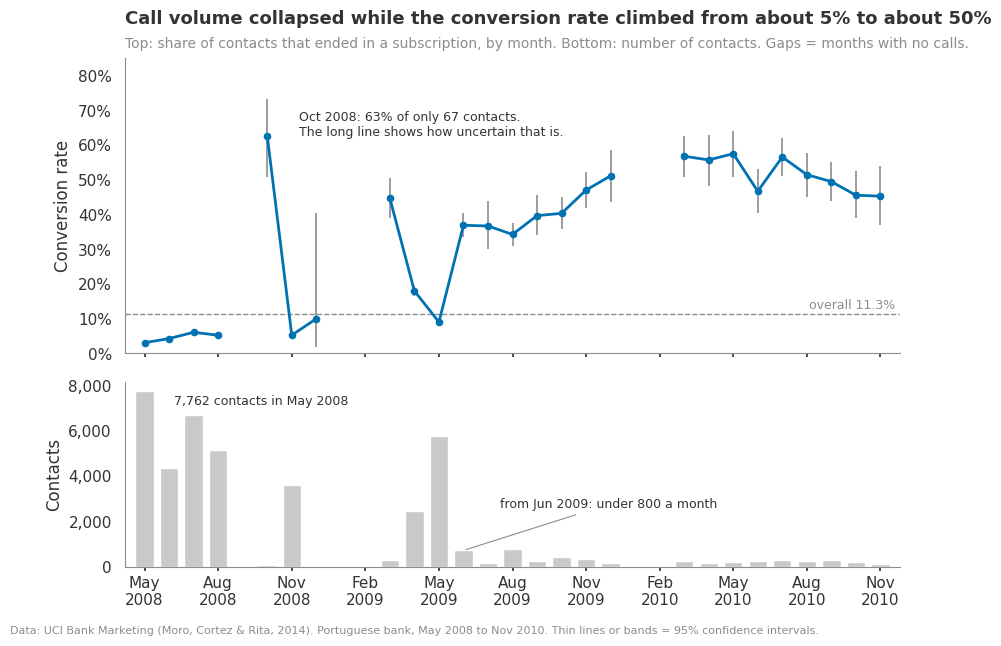

In [14]:
def label_time_axis(ax):
    """Label every third month, e.g. 'May' with the year underneath."""
    ticks = month_positions[::3]
    ax.set_xticks(ticks)
    ax.set_xticklabels([monthly.index[i].strftime("%b\n%Y") for i in ticks])
    ax.set_xlim(-0.8, len(monthly) - 0.2)


def draw_timeline_rate(ax):
    """Monthly conversion rate with confidence intervals."""
    # NaN months break the line automatically, which is what we want for months with no calls
    ax.plot(month_positions, monthly["rate"], color=ACCENT, linewidth=2, marker="o", markersize=4.5, zorder=3)
    draw_intervals(ax, month_positions, monthly, colour=MID)
    ax.axhline(overall_rate, color=MID, linewidth=1, linestyle="--")
    ax.text(len(monthly) - 0.4, overall_rate + 0.015, f"overall {pct(overall_rate)}", color=MID, fontsize=9, ha="right")
    ax.set_ylim(0, 0.85)
    percent_axis(ax.yaxis)
    ax.set_ylabel("Conversion rate")
    label_time_axis(ax)


def draw_timeline_volume(ax):
    """Number of contacts per month."""
    ax.bar(month_positions, monthly["contacts"].fillna(0), color=LIGHT, width=0.75)
    thousands_axis(ax.yaxis)
    ax.set_ylabel("Contacts")
    label_time_axis(ax)


fig, (ax_rate, ax_volume) = plt.subplots(2, 1, figsize=(10, 6.6), sharex=True,
                                         gridspec_kw={"height_ratios": [1.6, 1], "hspace": 0.12})
draw_timeline_rate(ax_rate)
draw_timeline_volume(ax_volume)

# Two short annotations that point the reader at the story
ax_rate.annotate("Oct 2008: 63% of only 67 contacts.\nThe long line shows how uncertain that is.",
                 xy=(5, 0.627), xytext=(6.3, 0.66), fontsize=9, color=DARK, va="center")
ax_volume.annotate("7,762 contacts in May 2008", xy=(0, 7762), xytext=(1.2, 7300), fontsize=9, color=DARK, va="center")
ax_volume.annotate("from Jun 2009: under 800 a month", xy=(13, 715), xytext=(14.5, 2600), fontsize=9, color=DARK,
                   arrowprops={"arrowstyle": "-", "color": MID, "linewidth": 0.8})

add_titles(ax_rate, "Call volume collapsed while the conversion rate climbed from about 5% to about 50%",
           "Top: share of contacts that ended in a subscription, by month. Bottom: number of contacts. Gaps = months with no calls.")
add_source(fig, y=0.02)
save(fig, "01_timeline_rate_and_volume.png")
plt.show()

**Takeaway.** The campaign changed character completely. In 2008 the bank made 27,682 contacts and converted 4.8% of them; in 2010 it made 2,058 contacts and converted 52.1%. Any comparison that ignores *when* a call was made is mostly comparing 2008 with 2009-2010. The following charts keep coming back to this.

### Question 2. Which period delivered the subscriptions?

**Chart choice:** paired horizontal bars. For each year, one bar for its share of all contacts and one for its share of all subscriptions. If effort and results were in proportion, the two bars would have the same length.

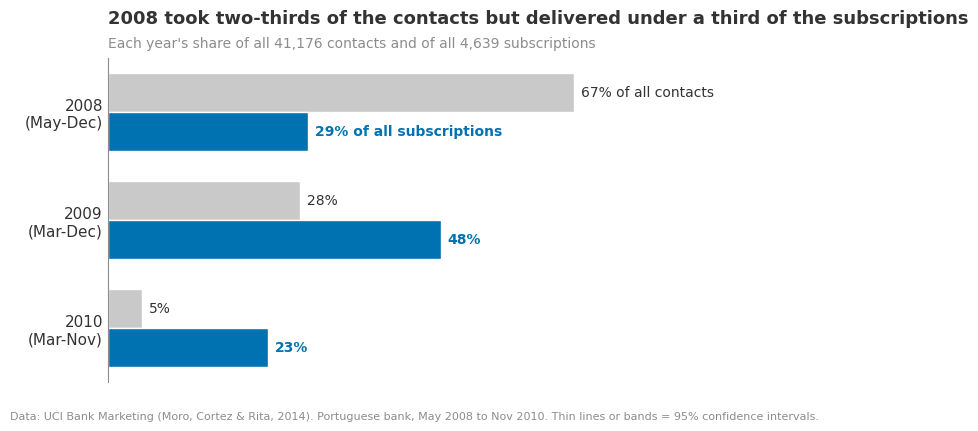

In [15]:
YEAR_LABEL = {2008: "2008\n(May-Dec)", 2009: "2009\n(Mar-Dec)", 2010: "2010\n(Mar-Nov)"}


def draw_year_shares(ax):
    """Share of contacts (grey) and share of subscriptions (accent) per year."""
    positions = np.arange(len(yearly))
    bar_height = 0.36
    ax.barh(positions - bar_height / 2, yearly["share_of_contacts"], height=bar_height, color=LIGHT)
    ax.barh(positions + bar_height / 2, yearly["share_of_subscriptions"], height=bar_height, color=ACCENT)

    # Direct labels at the end of every bar; the first pair also says what the bars are
    for position, (year, row) in zip(positions, yearly.iterrows()):
        first = position == 0
        ax.text(row["share_of_contacts"] + 0.01, position - bar_height / 2,
                pct(row["share_of_contacts"], 0) + (" of all contacts" if first else ""),
                va="center", color=DARK, fontsize=10)
        ax.text(row["share_of_subscriptions"] + 0.01, position + bar_height / 2,
                pct(row["share_of_subscriptions"], 0) + (" of all subscriptions" if first else ""),
                va="center", color=ACCENT, fontsize=10, fontweight="bold")

    ax.set_yticks(positions)
    ax.set_yticklabels([YEAR_LABEL[year] for year in yearly.index])
    ax.invert_yaxis()                 # 2008 at the top
    ax.set_xlim(0, 0.95)
    ax.xaxis.set_visible(False)       # the bars are labelled, so the axis is not needed
    ax.spines["bottom"].set_visible(False)
    ax.tick_params(axis="y", length=0)


fig, ax = plt.subplots(figsize=(8.5, 4.2))
draw_year_shares(ax)
add_titles(ax, "2008 took two-thirds of the contacts but delivered under a third of the subscriptions",
           "Each year's share of all 41,176 contacts and of all 4,639 subscriptions")
add_source(fig, y=0.04)
save(fig, "02_share_of_contacts_vs_subscriptions_by_year.png")
plt.show()

**Takeaway.** 2008 accounts for 67% of the contacts and 29% of the subscriptions. The 2,058 contacts of 2010 are only 5% of the effort and still brought 23% of all subscriptions. The conversions came disproportionately from the later, much smaller campaigns.

### Question 3. Are some calendar months better than others?

**Chart choice:** a dot plot of the conversion rate per calendar month next to a bar chart of the number of contacts, sharing the same rows. A table of rates alone would suggest "call in March and December". The volume bars show why that conclusion is not safe.

In [16]:
MONTH_ORDER = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]  # no calls in Jan or Feb

by_month = rate_table(df, "month").reindex(MONTH_ORDER)

# How many of each calendar month's contacts were made in 2008 (the low-conversion year)?
by_month["share_made_in_2008"] = df.groupby("month")["year"].apply(lambda s: (s == 2008).mean())
by_month.round(3)

,contacts,subscriptions,rate,ci_low,ci_high,share_made_in_2008
month,,,,,,
mar,546,276,0.505,0.464,0.547,0.000
apr,2631,539,0.205,0.190,0.221,0.000
may,13767,886,0.064,0.060,0.069,0.564
jun,5318,559,0.105,0.097,0.114,0.822
jul,7169,648,0.090,0.084,0.097,0.932
aug,6176,655,0.106,0.099,0.114,0.838
sep,570,256,0.449,0.409,0.490,0.000
oct,717,315,0.439,0.403,0.476,0.093
nov,4100,416,0.101,0.093,0.111,0.882


In [17]:
best_months = by_month[by_month["rate"] > 0.40]   # the months that look best
print("Months with a rate above 40%:", list(best_months.index))
print("Their contacts:", int(best_months["contacts"].sum()),
      f"= {pct(best_months['contacts'].sum() / total_contacts)} of all contacts")
in_best = df[df["month"].isin(best_months.index)]
print("Share of those contacts made in 2009 or 2010:", pct((in_best["year"] > 2008).mean()))

Months with a rate above 40%: ['mar', 'sep', 'oct', 'dec']
Their contacts: 2015 = 4.9% of all contacts
Share of those contacts made in 2009 or 2010: 96.2%


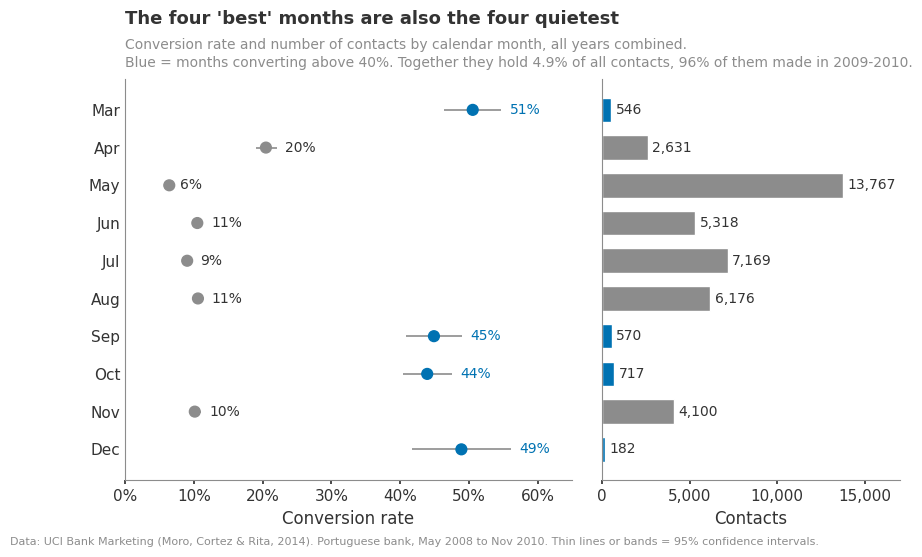

In [18]:
fig, (ax_rate, ax_volume) = plt.subplots(1, 2, figsize=(10, 5.2), sharey=True,
                                         gridspec_kw={"width_ratios": [1.5, 1], "wspace": 0.08})
positions = np.arange(len(by_month))
colours = [ACCENT if rate > 0.40 else MID for rate in by_month["rate"]]

# Left panel: conversion rate as a dot, with its confidence interval
draw_intervals(ax_rate, positions, by_month, horizontal=True, colour=MID)
ax_rate.scatter(by_month["rate"], positions, color=colours, s=60, zorder=3)
for position, (month, row) in zip(positions, by_month.iterrows()):
    ax_rate.text(row["ci_high"] + 0.012, position, pct(row["rate"], 0), va="center", fontsize=10,
                 color=ACCENT if row["rate"] > 0.40 else DARK)
ax_rate.set_yticks(positions)
ax_rate.set_yticklabels([month.capitalize() for month in by_month.index])
ax_rate.invert_yaxis()                       # March at the top
ax_rate.set_xlim(0, 0.65)
percent_axis(ax_rate.xaxis)
ax_rate.set_xlabel("Conversion rate")
ax_rate.tick_params(axis="y", length=0)

# Right panel: number of contacts
ax_volume.barh(positions, by_month["contacts"], color=colours, height=0.65)
for position, contacts in zip(positions, by_month["contacts"]):
    ax_volume.text(contacts + 250, position, f"{contacts:,}", va="center", fontsize=10, color=DARK)
ax_volume.set_xlim(0, 17000)
thousands_axis(ax_volume.xaxis)
ax_volume.set_xlabel("Contacts")
ax_volume.tick_params(axis="y", length=0)

add_titles(ax_rate, "The four 'best' months are also the four quietest",
           "Conversion rate and number of contacts by calendar month, all years combined.\n"
           "Blue = months converting above 40%. Together they hold 4.9% of all contacts, 96% of them made in 2009-2010.")
add_source(fig, y=0.0)
save(fig, "03_calendar_month_rate_vs_volume.png")
plt.show()

**Takeaway.** March, September, October and December convert at 44-51%, against 6% for May. But those four months together hold only 2,015 contacts (4.9% of the total), and 96% of them were made in 2009-2010, when every month converted well. May is dominated by the 7,762 contacts of May 2008. This chart is evidence about *which years the calls were made in*, not evidence that the calendar month itself matters. A seasonal effect cannot be confirmed or ruled out with this data.

### Question 4. Does calling a mobile work better than calling a landline?

**Chart choice:** a dumbbell chart (two dots joined by a line) for all contacts and then for each year separately. The pooled comparison mixes the channel with the period: in May and June 2008 the bank called landlines only. Comparing the channels *within* each year removes most of that mix-up.

In [19]:
by_channel = rate_table(df, "channel")
by_year_channel = rate_table(df, ["year", "channel"])

print(by_channel.round(3))
print()
print(by_year_channel.round(3))

          contacts  subscriptions   rate  ci_low  ci_high
channel                                                  
landline     15041            787  0.052   0.049    0.056
mobile       26135           3852  0.147   0.143    0.152

               contacts  subscriptions   rate  ci_low  ci_high
year channel                                                  
2008 landline     13712            539  0.039   0.036    0.043
     mobile       13970            800  0.057   0.054    0.061
2009 landline       941            138  0.147   0.125    0.171
     mobile       10495           2089  0.199   0.192    0.207
2010 landline       388            110  0.284   0.241    0.330
     mobile        1670            963  0.577   0.553    0.600


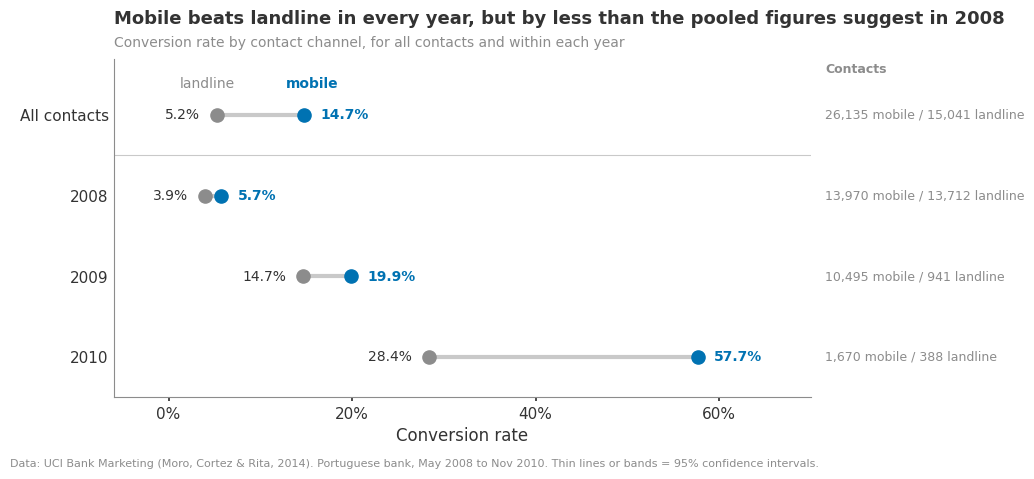

In [20]:
def draw_channel_dumbbell(ax, show_counts=True):
    """Landline vs mobile conversion rate, for all contacts and for each year."""
    rows = [("All contacts", by_channel)] + [(str(year), by_year_channel.loc[year]) for year in yearly.index]

    for position, (label, table) in enumerate(rows):
        landline, mobile = table.loc["landline"], table.loc["mobile"]
        ax.plot([landline["rate"], mobile["rate"]], [position, position], color=LIGHT, linewidth=3, zorder=1)
        ax.scatter(landline["rate"], position, color=MID, s=90, zorder=3)
        ax.scatter(mobile["rate"], position, color=ACCENT, s=90, zorder=3)
        ax.text(landline["rate"] - 0.018, position, pct(landline["rate"]), ha="right", va="center", color=DARK, fontsize=10)
        ax.text(mobile["rate"] + 0.018, position, pct(mobile["rate"]), ha="left", va="center",
                color=ACCENT, fontsize=10, fontweight="bold")
        if position == 0:   # name the two dots once, above the first row
            ax.text(landline["rate"] + 0.02, position - 0.34, "landline", ha="right", color=MID, fontsize=10)
            ax.text(mobile["rate"] - 0.02, position - 0.34, "mobile", ha="left", color=ACCENT, fontsize=10, fontweight="bold")
        if show_counts:     # group sizes in the right margin
            ax.text(1.02, position, f"{int(mobile['contacts']):,} mobile / {int(landline['contacts']):,} landline",
                    transform=ax.get_yaxis_transform(), va="center", fontsize=9, color=MID)

    ax.axhline(0.5, color=LIGHT, linewidth=0.8)     # thin rule between the pooled row and the yearly rows
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([label for label, table in rows])
    ax.set_ylim(len(rows) - 0.5, -0.7)              # reversed limits: first row at the top
    ax.set_xlim(-0.06, 0.70)
    ax.set_xticks([0, 0.2, 0.4, 0.6])
    percent_axis(ax.xaxis)
    ax.set_xlabel("Conversion rate")
    ax.tick_params(axis="y", length=0)


fig, ax = plt.subplots(figsize=(9, 4.4))
draw_channel_dumbbell(ax)
ax.text(1.02, -0.52, "Contacts", transform=ax.get_yaxis_transform(), fontsize=9, color=MID, fontweight="bold")
add_titles(ax, "Mobile beats landline in every year, but by less than the pooled figures suggest in 2008",
           "Conversion rate by contact channel, for all contacts and within each year")
add_source(fig, y=-0.03)
save(fig, "04_mobile_vs_landline_by_year.png")
plt.show()

**Takeaway.** Pooled, mobile contacts convert at 14.7% and landline contacts at 5.2%, almost three times as well. Within 2008 the gap is much smaller (5.7% against 3.9%), because the pooled figure also reflects that landline calls were concentrated in the weak months of 2008. The mobile advantage does appear in all three years (2009: 19.9% vs 14.7%; 2010: 57.7% vs 28.4%), so it is a consistent association. The data cannot say whether the channel itself causes it or whether mobile numbers simply belong to different kinds of clients.

### Question 5. Does the result of the previous campaign predict this one?

**Chart choice:** three sorted horizontal bars with confidence intervals and group sizes. A simple comparison of a few categories is exactly what a bar chart is for.

In [21]:
OUTCOME_LABEL = {"success": "Subscribed in the\nprevious campaign",
                 "failure": "Declined in the\nprevious campaign",
                 "nonexistent": "Not part of a\nprevious campaign"}

by_outcome = rate_table(df, "poutcome").sort_values("rate", ascending=False)
by_outcome.round(3)

,contacts,subscriptions,rate,ci_low,ci_high
poutcome,,,,,
success,1373,894,0.651,0.626,0.676
failure,4252,605,0.142,0.132,0.153
nonexistent,35551,3140,0.088,0.085,0.091


The same split within each year, to see whether the pattern survives once the period is held fixed:

In [22]:
by_year_outcome = rate_table(df, ["year", "poutcome"])
by_year_outcome[["contacts", "rate"]].unstack("year").round(3)

contacts              rate              
year            2008  2009 2010   2008   2009   2010
poutcome                                            
failure          699  2986  567  0.034  0.129  0.346
nonexistent    26948  7760  843  0.049  0.187  0.448
success           35   690  648  0.086  0.568  0.770

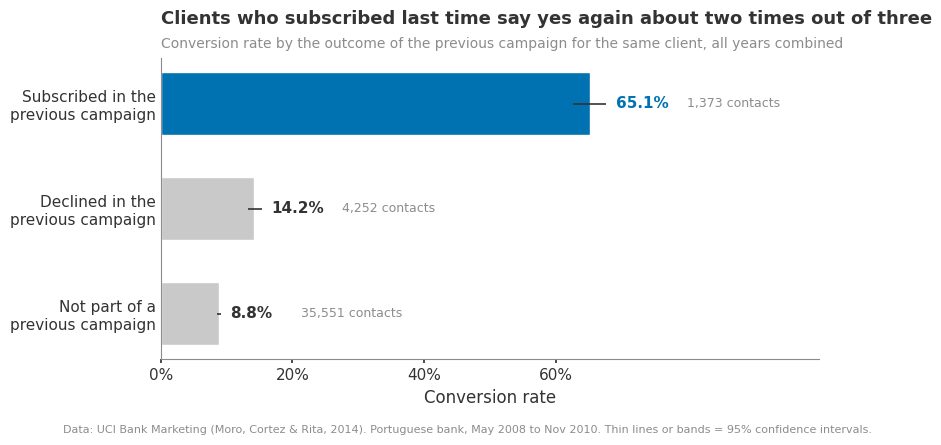

In [23]:
def draw_previous_outcome(ax):
    """Conversion rate by outcome of the previous campaign."""
    positions = np.arange(len(by_outcome))
    colours = [ACCENT if outcome == "success" else LIGHT for outcome in by_outcome.index]
    ax.barh(positions, by_outcome["rate"], color=colours, height=0.6)
    draw_intervals(ax, positions, by_outcome, horizontal=True)
    for position, (outcome, row) in zip(positions, by_outcome.iterrows()):
        # xytext is a shift in points (1/72 inch) to the right of the interval, so labels never collide
        ax.annotate(pct(row["rate"]), xy=(row["ci_high"], position), xytext=(7, 0), textcoords="offset points",
                    va="center", fontsize=11, fontweight="bold", color=ACCENT if outcome == "success" else DARK)
        ax.annotate(f"{int(row['contacts']):,} contacts", xy=(row["ci_high"], position), xytext=(58, 0),
                    textcoords="offset points", va="center", fontsize=9, color=MID)
    ax.set_yticks(positions)
    ax.set_yticklabels([OUTCOME_LABEL[outcome] for outcome in by_outcome.index])
    ax.invert_yaxis()
    ax.set_xlim(0, 1.0)
    ax.set_xticks([0, 0.2, 0.4, 0.6])
    percent_axis(ax.xaxis)
    ax.set_xlabel("Conversion rate")
    ax.tick_params(axis="y", length=0)


fig, ax = plt.subplots(figsize=(8.5, 3.9))
draw_previous_outcome(ax)
add_titles(ax, "Clients who subscribed last time say yes again about two times out of three",
           "Conversion rate by the outcome of the previous campaign for the same client, all years combined")
add_source(fig, y=-0.06)
save(fig, "05_previous_campaign_outcome.png")
plt.show()

**Takeaway.** Clients who subscribed in the previous campaign convert at 65.1% (894 of 1,373), against 8.8% for clients who were not part of a previous campaign. This is the largest gap in the whole dataset and it holds within 2009 (56.8% vs 18.7%) and 2010 (77.0% vs 44.8%); in 2008 only 35 such clients were contacted, too few to judge.

One caution about the middle bar. Pooled, clients who *declined* last time (14.2%) look better than new clients (8.8%). Within every single year it is the other way round (2008: 3.4% vs 4.9%; 2009: 12.9% vs 18.7%; 2010: 34.6% vs 44.8%). The pooled order is an artefact of timing: previous decliners were mostly called in 2009-2010. This is a textbook case of Simpson's paradox and a reason not to read the pooled bar as "a previous no is a good sign".

### Question 6. Is it worth calling the same client again and again?

The column `campaign` counts how many times the client was contacted during this campaign, including the last call.

**Chart choice:** a line per year with a confidence band, because the number of calls is an ordered scale and the question is about a trend. The lines are split by year because 2008 used more repeat calls than later years (see the first output below), so a pooled line would again mix repeat calls with the period.

In [24]:
print("Average number of calls per client, by year:")
print(df.groupby("year")["campaign"].mean().round(2))

CALLS_ORDER = ["1", "2", "3", "4", "5", "6+"]
by_year_calls = rate_table(df, ["year", "calls_band"])
by_year_calls[["contacts", "rate"]].unstack("year").reindex(CALLS_ORDER).round(3)

Average number of calls per client, by year:
year
2008    2.80
2009    2.13
2010    1.91
Name: campaign, dtype: float64


contacts               rate              
year           2008  2009  2010   2008   2009   2010
calls_band                                          
1             11054  5495  1085  0.049  0.216  0.525
2              7006  3038   524  0.049  0.194  0.531
3              3827  1277   236  0.050  0.193  0.572
4              1904   639   107  0.048  0.169  0.458
5              1144   410    45  0.045  0.120  0.444
6+             2747   577    61  0.044  0.078  0.344

In [25]:
# How much of the calling effort went to clients who were called six times or more?
many_calls = df[df["campaign"] >= 6]
few_calls = df[df["campaign"] <= 3]
total_calls_made = df["campaign"].sum()   # every row counts as many calls as the client received

print(f"Clients called 6+ times: {len(many_calls):,}")
print(f"  their share of all calls made:      {pct(many_calls['campaign'].sum() / total_calls_made)}")
print(f"  their share of all subscriptions:   {pct(many_calls['subscribed'].sum() / total_subscriptions)}")
print(f"Share of subscriptions from clients called 1-3 times: {pct(few_calls['subscribed'].sum() / total_subscriptions)}")

Clients called 6+ times: 3,385
  their share of all calls made:      30.6%
  their share of all subscriptions:   4.0%
Share of subscriptions from clients called 1-3 times: 88.0%


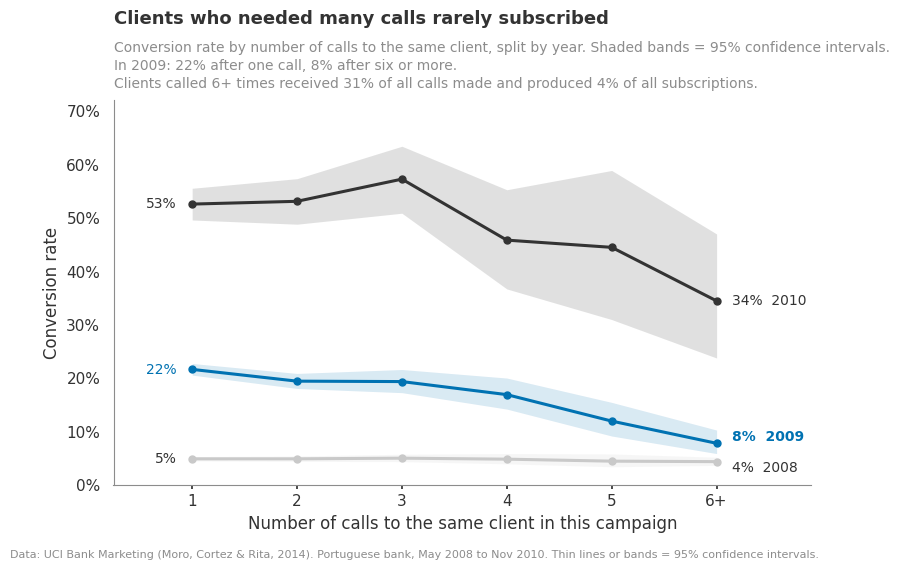

In [26]:
def draw_repeat_calls(ax):
    """Conversion rate by number of calls to the same client, one line per year."""
    positions = np.arange(len(CALLS_ORDER))
    for year in yearly.index:
        table = by_year_calls.loc[year].reindex(CALLS_ORDER)
        colour = YEAR_COLOUR[year]
        ax.fill_between(positions, table["ci_low"], table["ci_high"], color=colour, alpha=0.15, linewidth=0)
        ax.plot(positions, table["rate"], color=colour, linewidth=2.2, marker="o", markersize=5)
        # direct labels: first value on the left, year and last value on the right
        ax.text(-0.15, table["rate"].iloc[0], pct(table["rate"].iloc[0], 0), ha="right", va="center",
                fontsize=10, color=ACCENT if year == 2009 else DARK)
        nudge = {2008: -0.012, 2009: 0.012, 2010: 0}[year]   # keeps the 2008 and 2009 labels apart
        ax.text(positions[-1] + 0.15, table["rate"].iloc[-1] + nudge, f"{pct(table['rate'].iloc[-1], 0)}  {year}",
                ha="left", va="center", fontsize=10, color=ACCENT if year == 2009 else DARK,
                fontweight="bold" if year == 2009 else "normal")
    ax.set_xticks(positions)
    ax.set_xticklabels(CALLS_ORDER)
    ax.set_xlim(-0.75, positions[-1] + 0.9)
    ax.set_ylim(0, 0.72)
    percent_axis(ax.yaxis)
    ax.set_xlabel("Number of calls to the same client in this campaign")
    ax.set_ylabel("Conversion rate")


fig, ax = plt.subplots(figsize=(9, 5))
draw_repeat_calls(ax)
add_titles(ax, "Clients who needed many calls rarely subscribed",
           "Conversion rate by number of calls to the same client, split by year. Shaded bands = 95% confidence intervals.\n"
           "In 2009: 22% after one call, 8% after six or more.\n"
           "Clients called 6+ times received 31% of all calls made and produced 4% of all subscriptions.")
add_source(fig, y=-0.02)
save(fig, "06_repeat_calls_by_year.png")
plt.show()

**Takeaway.** In 2009 the conversion rate falls steadily with the number of calls: 21.6% for clients reached with one call, 7.8% for clients called six or more times. 2010 shows the same direction with a wide uncertainty band (only 61 clients were called 6+ times). In 2008 the rate was about 5% no matter how often the client was called. Across the whole period, the 3,385 clients called six or more times absorbed 30.6% of all calls made and returned 4.0% of the subscriptions, while 88.0% of subscriptions came from clients called at most three times.

This does not prove that extra calls *reduce* interest: clients who are easy to convince say yes early and drop out of the calling list, so the ones still being called are the reluctant ones. Either way, the calls after the third or fourth attempt bought very few subscriptions.

### Question 7. Which age groups respond best?

**Chart choice:** small multiples, the same bar chart repeated once per year with a shared y axis. A single pooled chart would be misleading here, because the age mix of the people called changed over time: nobody aged 65 or over was contacted in 2008.

In [27]:
AGE_ORDER = ["17-24", "25-34", "35-44", "45-54", "55-64", "65+"]

by_age = rate_table(df, "age_band")
by_year_age = rate_table(df, ["year", "age_band"])

print("All years combined:")
print(by_age.round(3))
print()
print("Within each year:")
by_year_age[["contacts", "rate"]].unstack("year").round(3)

All years combined:
          contacts  subscriptions   rate  ci_low  ci_high
age_band                                                 
17-24         1067            256  0.240   0.215    0.266
25-34        13684           1666  0.122   0.116    0.127
35-44        13495           1168  0.087   0.082    0.091
45-54         8702            752  0.086   0.081    0.093
55-64         3566            484  0.136   0.125    0.147
65+            662            313  0.473   0.435    0.511

Within each year:


contacts                  rate              
year         2008    2009   2010   2008   2009   2010
age_band                                             
17-24       397.0   513.0  157.0  0.063  0.292  0.516
25-34      8638.0  4270.0  776.0  0.053  0.196  0.470
35-44      9550.0  3562.0  383.0  0.047  0.140  0.564
45-54      6631.0  1790.0  281.0  0.042  0.182  0.534
55-64      2466.0   881.0  219.0  0.050  0.275  0.543
65+           NaN   420.0  242.0    NaN  0.407  0.587

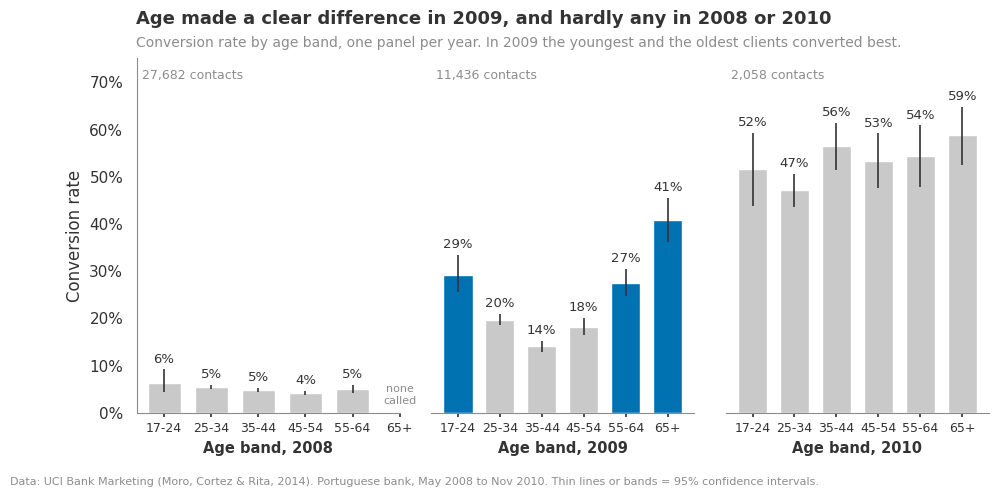

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4.6), sharey=True, gridspec_kw={"wspace": 0.12})
positions = np.arange(len(AGE_ORDER))

for ax, year in zip(axes, yearly.index):
    table = by_year_age.loc[year].reindex(AGE_ORDER)   # 65+ has no row in 2008, so it becomes NaN
    # Only the 2009 panel uses the accent, and only for the youngest and oldest groups
    colours = [ACCENT if (year == 2009 and band in ["17-24", "55-64", "65+"]) else LIGHT for band in AGE_ORDER]
    ax.bar(positions, table["rate"], color=colours, width=0.7)
    draw_intervals(ax, positions, table)
    for position, (band, row) in zip(positions, table.iterrows()):
        if pd.isna(row["rate"]):
            ax.text(position, 0.015, "none\ncalled", ha="center", va="bottom", fontsize=8, color=MID)
        else:
            ax.text(position, row["ci_high"] + 0.015, pct(row["rate"], 0), ha="center", fontsize=9.5, color=DARK)
    ax.set_xticks(positions)
    ax.set_xticklabels(AGE_ORDER, fontsize=9)
    ax.set_xlabel(f"Age band, {year}", fontsize=10.5, fontweight="bold")
    ax.text(0.02, 0.97, f"{yearly.loc[year, 'contacts']:,} contacts", transform=ax.transAxes,
            fontsize=9, color=MID, va="top")
    ax.set_ylim(0, 0.75)
    percent_axis(ax.yaxis)
    if ax is not axes[0]:                      # only the first panel needs a y axis
        ax.spines["left"].set_visible(False)
        ax.tick_params(axis="y", length=0)

axes[0].set_ylabel("Conversion rate")
add_titles(axes[0], "Age made a clear difference in 2009, and hardly any in 2008 or 2010",
           "Conversion rate by age band, one panel per year. In 2009 the youngest and the oldest clients converted best.")
add_source(fig, y=-0.03)
save(fig, "07_age_bands_by_year.png")
plt.show()

**Takeaway.** Pooled over all years, clients aged 65+ convert at 47.3% and those aged 17-24 at 24.0%, against 8.7% for ages 35-44. Part of that is timing: the 662 contacts with clients aged 65+ were all made in 2009-2010. Looking within years, age made little difference in 2008 (4-6% everywhere) or in 2010 (47-59%, with overlapping intervals). In 2009 there is a clear U-shape: 40.7% for 65+, 29.2% for 17-24 and 27.5% for 55-64, against 14.0% for ages 35-44. So the "young and old respond best" pattern is real in one year out of three, and smaller than the pooled figures suggest.

### Question 8. Which job types respond best?

**Chart choice:** a dot plot with one row per job and one dot per year. Twelve categories with three values each would be 36 bars; dots on a shared scale are much easier to compare, and the horizontal spread between the three dots shows directly how much the period matters compared with the job.

In [29]:
JOB_LABEL = {"admin.": "Admin", "blue-collar": "Blue-collar", "entrepreneur": "Entrepreneur", "housemaid": "Housemaid",
             "management": "Management", "retired": "Retired", "self-employed": "Self-employed", "services": "Services",
             "student": "Student", "technician": "Technician", "unemployed": "Unemployed", "unknown": "Unknown"}

by_job = rate_table(df, "job").sort_values("rate", ascending=False)
by_year_job = rate_table(df, ["year", "job"])

print("All years combined:")
print(by_job.round(3))
print()
print("Within each year:")
by_year_job[["contacts", "rate"]].unstack("year").round(3)

All years combined:
               contacts  subscriptions   rate  ci_low  ci_high
job                                                           
student             875            275  0.314   0.284    0.346
retired            1718            434  0.253   0.233    0.274
unemployed         1014            144  0.142   0.122    0.165
admin.            10419           1351  0.130   0.123    0.136
management         2924            328  0.112   0.101    0.124
unknown             330             37  0.112   0.082    0.151
technician         6739            730  0.108   0.101    0.116
self-employed      1421            149  0.105   0.090    0.122
housemaid          1060            106  0.100   0.083    0.120
entrepreneur       1456            124  0.085   0.072    0.101
services           3967            323  0.081   0.073    0.090
blue-collar        9253            638  0.069   0.064    0.074

Within each year:


contacts              rate              
year              2008  2009 2010   2008   2009   2010
job                                                   
admin.            6827  2951  641  0.049  0.228  0.534
blue-collar       6471  2646  136  0.047  0.101  0.493
entrepreneur      1066   364   26  0.054  0.151  0.423
housemaid          824   181   55  0.033  0.265  0.564
management        2015   789  120  0.054  0.200  0.517
retired            795   649  274  0.059  0.365  0.547
self-employed      992   376   53  0.048  0.205  0.453
services          2719  1125  123  0.049  0.122  0.439
student            193   473  209  0.073  0.321  0.522
technician        4870  1552  317  0.047  0.215  0.527
unemployed         662   266   86  0.036  0.274  0.547
unknown            248    64   18  0.052  0.234  0.500

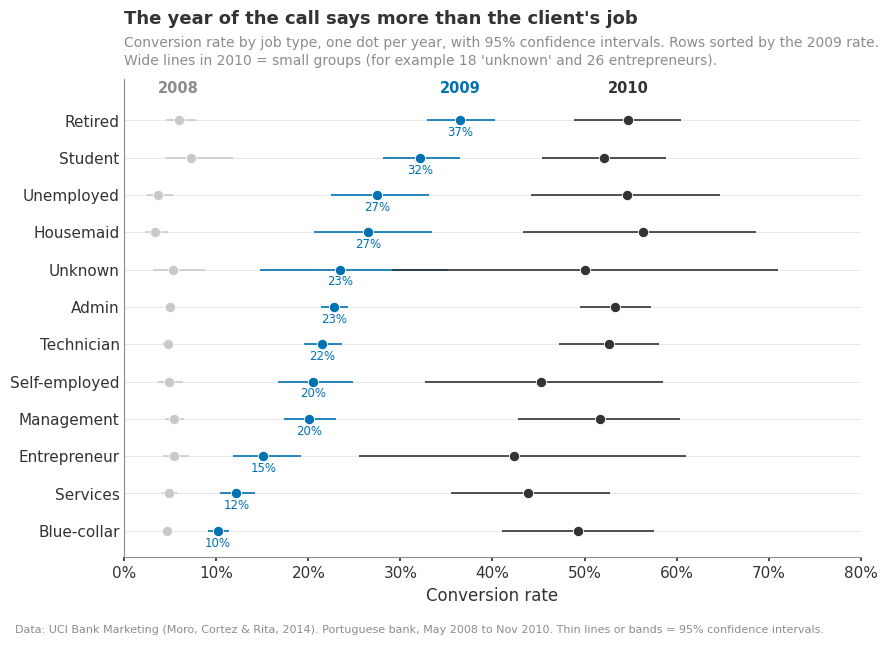

In [30]:
# Sort the rows by the 2009 rate, the year in which jobs differ most
job_order = by_year_job.loc[2009].sort_values("rate", ascending=False).index
positions = np.arange(len(job_order))

fig, ax = plt.subplots(figsize=(9.5, 6.2))
for year in yearly.index:
    table = by_year_job.loc[year].reindex(job_order)
    draw_intervals(ax, positions, table, horizontal=True, colour=YEAR_COLOUR[year])
    ax.scatter(table["rate"], positions, color=YEAR_COLOUR[year], s=55, zorder=3,
               edgecolor="white", linewidth=0.6)
    # name the year once, above the top row
    ax.text(table["rate"].iloc[0], -0.75, str(year), ha="center", fontsize=10.5,
            color=ACCENT if year == 2009 else (DARK if year == 2010 else MID), fontweight="bold")

# value labels for 2009 only, to keep the chart calm
table_2009 = by_year_job.loc[2009].reindex(job_order)
for position, (job, row) in zip(positions, table_2009.iterrows()):
    ax.text(row["rate"], position + 0.42, pct(row["rate"], 0), ha="center", fontsize=8.5, color=ACCENT)

ax.set_yticks(positions)
ax.set_yticklabels([JOB_LABEL[job] for job in job_order])
ax.set_ylim(len(job_order) - 0.3, -1.1)     # reversed limits: best 2009 job at the top
ax.set_xlim(0, 0.80)
percent_axis(ax.xaxis)
ax.set_xlabel("Conversion rate")
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", color=LIGHT, linewidth=0.5, alpha=0.6)   # faint row guides help the eye across

add_titles(ax, "The year of the call says more than the client's job",
           "Conversion rate by job type, one dot per year, with 95% confidence intervals. Rows sorted by the 2009 rate.\n"
           "Wide lines in 2010 = small groups (for example 18 'unknown' and 26 entrepreneurs).")
add_source(fig, y=0.0)
save(fig, "08_job_types_by_year.png")
plt.show()

**Takeaway.** For every job, the three dots are far apart: the distance between years is larger than the distance between jobs within a year. In 2008 all jobs converted at 3-7%. In 2010 all sit between 42% and 56% with wide, overlapping intervals. Only in 2009 do jobs separate clearly: retired clients (36.5%) and students (32.1%) at the top, services (12.2%) and blue-collar workers (10.1%) at the bottom. The pooled ranking (students 31.4%, retired 25.3%, blue-collar 6.9%) overstates these differences, because students and retired clients were contacted mostly in 2009-2010.

### Question 9. How much of this is the economy?

The dataset includes national economic indicators. The three-month Euribor interest rate fell from about 5% in 2008 to under 1% in 2009-2010, the period of the financial crisis.

**Chart choice:** four small line charts stacked on one shared time axis. The purpose is not to show one relationship but to show that several things changed *at the same time*, which is why their effects cannot be separated.

In [31]:
monthly[["rate", "euribor", "share_mobile", "share_contacted_before"]].dropna().round(3)

,rate,euribor,share_mobile,share_contacted_before
2008-05-01,0.031,4.858,0.000,0.000
2008-06-01,0.043,4.932,0.000,0.000
2008-07-01,0.061,4.962,0.852,0.000
2008-08-01,0.052,4.965,0.972,0.000
2008-10-01,0.627,4.924,0.015,0.000
2008-11-01,0.053,4.115,0.898,0.010
2008-12-01,0.100,3.493,0.200,0.000
2009-03-01,0.447,1.646,0.929,0.014
2009-04-01,0.180,1.412,0.933,0.027
2009-05-01,0.090,1.294,0.923,0.028


In [32]:
print("Correlation between monthly conversion rate and monthly average Euribor (26 months):",
      round(monthly["rate"].corr(monthly["euribor"]), 2))

low_rates = df[df["euribor3m"] < 2]
high_rates = df[df["euribor3m"] >= 2]
print(f"Euribor below 2%:  {len(low_rates):,} contacts, conversion {pct(low_rates['subscribed'].mean())}")
print(f"Euribor 2% and up: {len(high_rates):,} contacts, conversion {pct(high_rates['subscribed'].mean())}")

print()
print("Share of contacts to mobiles, by year:")
print(df.groupby("year")["channel"].apply(lambda s: (s == "mobile").mean()).round(3))
print("Share of contacts to clients contacted before, by year:")
print(df.groupby("year")["contacted_before"].apply(lambda s: (s == "yes").mean()).round(3))

Correlation between monthly conversion rate and monthly average Euribor (26 months): -0.68
Euribor below 2%:  13,494 contacts, conversion 24.5%
Euribor 2% and up: 27,682 contacts, conversion 4.8%

Share of contacts to mobiles, by year:
year
2008    0.505
2009    0.918
2010    0.811
Name: channel, dtype: float64
Share of contacts to clients contacted before, by year:
year
2008    0.001
2009    0.066
2010    0.352
Name: contacted_before, dtype: float64


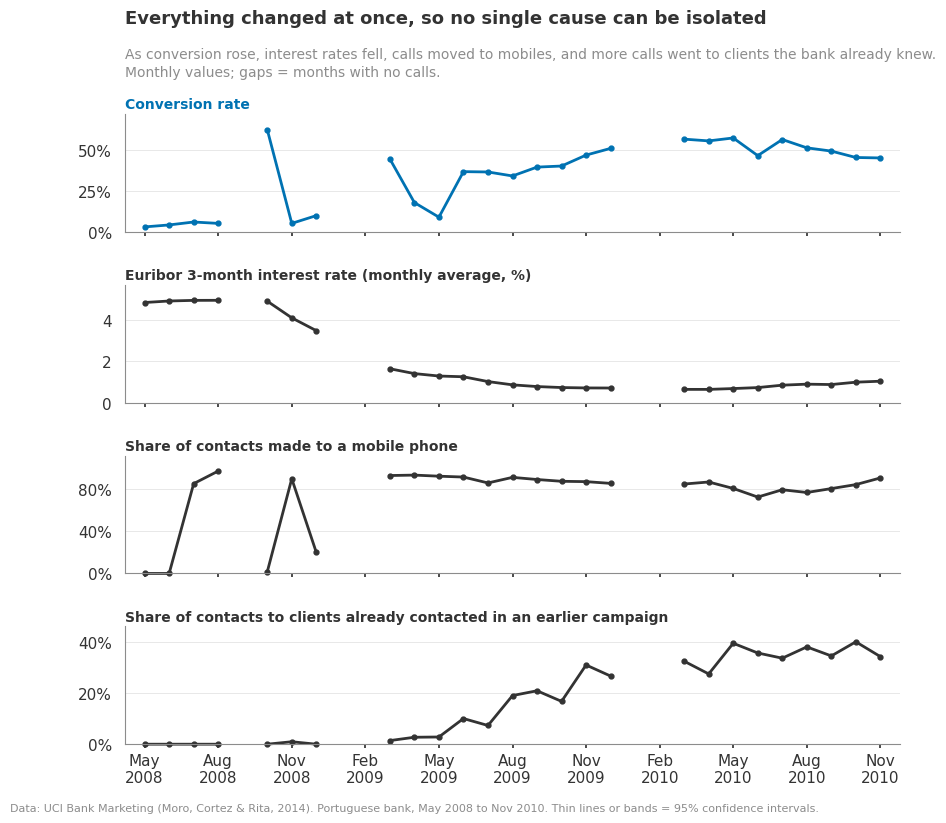

In [33]:
panels = [
    # column, panel label, colour, is it a percentage?
    ("rate", "Conversion rate", ACCENT, True),
    ("euribor", "Euribor 3-month interest rate (monthly average, %)", DARK, False),
    ("share_mobile", "Share of contacts made to a mobile phone", DARK, True),
    ("share_contacted_before", "Share of contacts to clients already contacted in an earlier campaign", DARK, True),
]

fig, axes = plt.subplots(len(panels), 1, figsize=(10, 8.4), sharex=True, gridspec_kw={"hspace": 0.45})
for ax, (column, label, colour, is_percentage) in zip(axes, panels):
    ax.plot(month_positions, monthly[column], color=colour, linewidth=2, marker="o", markersize=3.5,
            clip_on=False)   # clip_on=False keeps dots that sit exactly on 0% fully visible
    ax.set_title(label, loc="left", fontsize=10, color=colour, fontweight="bold", pad=4)
    ax.set_ylim(0, monthly[column].max() * 1.15)
    if is_percentage:
        percent_axis(ax.yaxis)
    ax.yaxis.set_major_locator(plt.MaxNLocator(3))   # at most three y ticks per small panel
    ax.grid(axis="y", color=LIGHT, linewidth=0.5, alpha=0.6)
    label_time_axis(ax)

fig.suptitle("Everything changed at once, so no single cause can be isolated", x=0.125, y=0.985, ha="left",
             fontsize=13, fontweight="bold")
fig.text(0.125, 0.94, "As conversion rose, interest rates fell, calls moved to mobiles, and more calls went to clients "
         "the bank already knew.\nMonthly values; gaps = months with no calls.", fontsize=10, color=MID, va="top",
         linespacing=1.35)
fig.subplots_adjust(top=0.86)
add_source(fig, y=0.04)
save(fig, "09_everything_changed_at_once.png")
plt.show()

**Takeaway.** Conversion is strongly tied to the economic climate: contacts made while Euribor was below 2% converted at 24.5%, those made at 2% or above at 4.8%, and the monthly correlation between Euribor and conversion is -0.68. But over the same months the bank also switched from landlines to mobiles (0% of contacts in May-June 2008, 72-93% in every month from March 2009), cut call volume by more than 90%, and increasingly called clients it had contacted before (0-1% in 2008, 28-40% in 2010). Month, channel, client selection and the economy moved together, so this data cannot tell how much each one contributed. Only a controlled test could.

### Question 10. What do successful calls look like?

**Important caveat first.** `duration` is the length of the call, which is only known *after* the call has happened, and a client who is subscribing naturally stays on the line longer. It can describe what a successful call looks like. It can **not** be used to decide whom to call, and "make calls longer" is not a valid recommendation from this chart.

**Chart choice:** two overlapping density curves (seaborn `kdeplot`) on a logarithmic time axis. Call lengths are very skewed (most calls are short, a few are very long), and a log axis spreads them out so both groups are visible.

In [34]:
df["duration_minutes"] = df["duration"] / 60

duration_summary = df.groupby("y")["duration_minutes"].describe().round(2)
print("Calls with a recorded length of 0 seconds:", int((df["duration"] == 0).sum()))
duration_summary

Calls with a recorded length of 0 seconds: 4


,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,36537.0,3.68,3.45,0.00,1.58,2.73,4.65,81.97
yes,4639.0,9.22,6.69,0.62,4.22,7.48,12.36,69.98


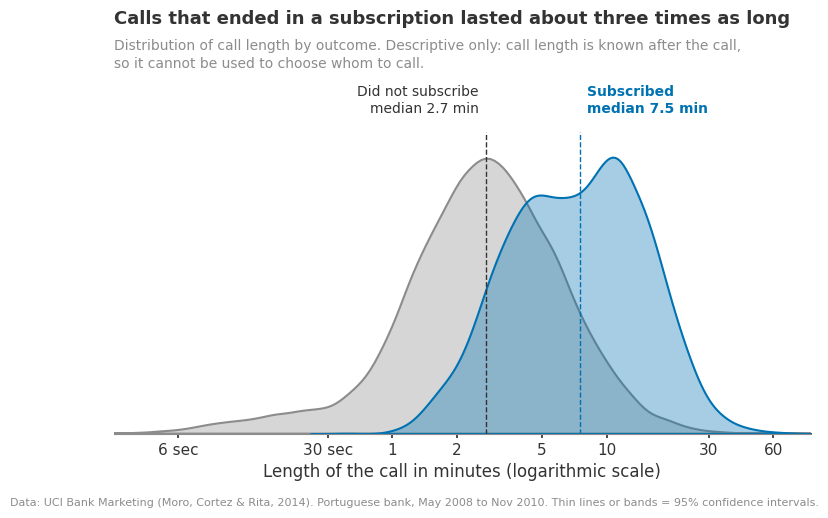

In [35]:
# A log axis cannot show 0, so the few zero-length calls are left out of this chart only
talked = df[df["duration"] > 0]
median_no = talked.loc[talked["y"] == "no", "duration_minutes"].median()
median_yes = talked.loc[talked["y"] == "yes", "duration_minutes"].median()

fig, ax = plt.subplots(figsize=(9, 4.6))
sns.kdeplot(data=talked[talked["y"] == "no"], x="duration_minutes", log_scale=True, fill=True,
            color=MID, alpha=0.35, linewidth=1.5, ax=ax)
sns.kdeplot(data=talked[talked["y"] == "yes"], x="duration_minutes", log_scale=True, fill=True,
            color=ACCENT, alpha=0.35, linewidth=1.5, ax=ax)

# Median lines and direct labels instead of a legend
top = ax.get_ylim()[1]
ax.set_ylim(0, top * 1.22)               # extra head-room so the labels sit above the curves
ax.vlines(median_no, 0, top * 1.04, color=DARK, linewidth=1, linestyle="--")
ax.vlines(median_yes, 0, top * 1.04, color=ACCENT, linewidth=1, linestyle="--")
ax.text(median_no / 1.08, top * 1.2, f"Did not subscribe\nmedian {median_no:.1f} min", ha="right", va="top", fontsize=10, color=DARK)
ax.text(median_yes * 1.08, top * 1.2, f"Subscribed\nmedian {median_yes:.1f} min", ha="left", va="top", fontsize=10,
        color=ACCENT, fontweight="bold")

ax.set_xlim(0.05, 90)
ax.set_xticks([0.1, 0.5, 1, 2, 5, 10, 30, 60])
ax.set_xticklabels(["6 sec", "30 sec", "1", "2", "5", "10", "30", "60"])
ax.minorticks_off()
ax.set_xlabel("Length of the call in minutes (logarithmic scale)")
ax.yaxis.set_visible(False)              # the height of a density curve has no intuitive unit
ax.spines["left"].set_visible(False)

add_titles(ax, "Calls that ended in a subscription lasted about three times as long",
           "Distribution of call length by outcome. Descriptive only: call length is known after the call,\n"
           "so it cannot be used to choose whom to call.")
add_source(fig, y=-0.03)
save(fig, "10_call_duration_by_outcome.png")
plt.show()

**Takeaway.** The median successful call lasted 7.5 minutes, the median unsuccessful one 2.7 minutes. That is what one would expect (explaining and agreeing a product takes time), and the direction of cause runs mostly from "client is interested" to "call is long", not the other way round. The useful operational reading is modest: the middle half of successful calls lasted between 4.2 and 12.4 minutes of agent time, which matters for staffing, not for targeting.

---
## 4. Summary figure

One page with the five charts that carry the main story. The drawing functions defined above are reused, so the summary always shows exactly the same numbers as the individual charts.

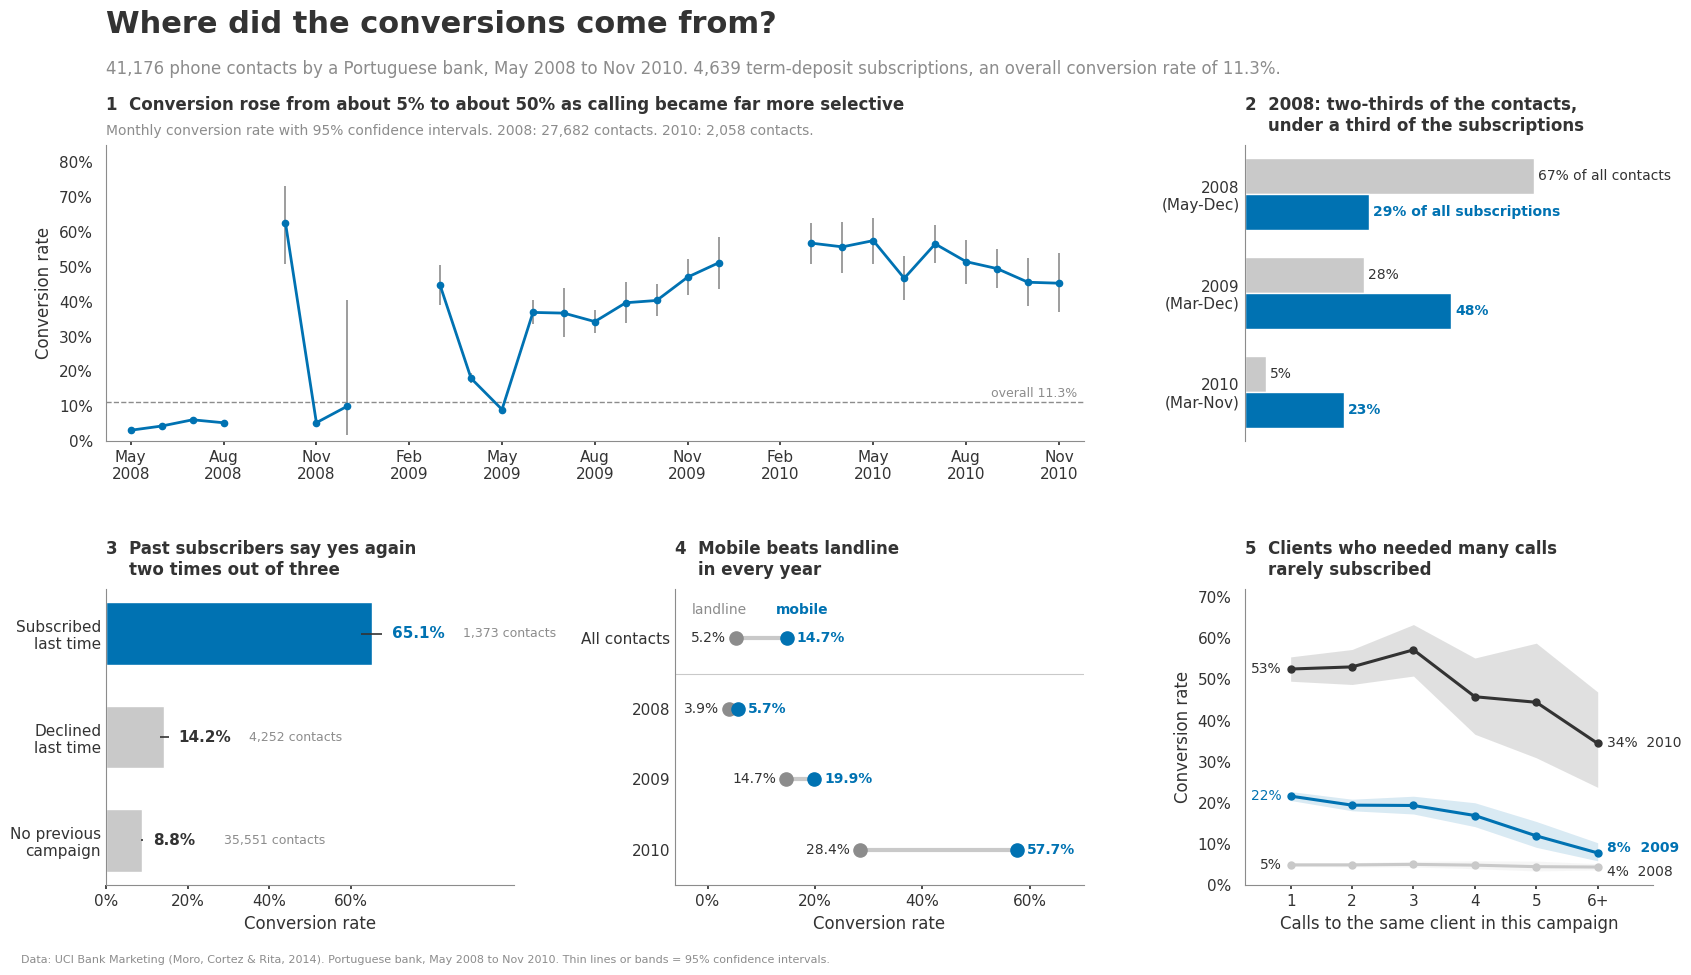

In [36]:
fig = plt.figure(figsize=(17, 10))
grid = fig.add_gridspec(2, 6, hspace=0.5, wspace=1.3, left=0.06, right=0.97, top=0.83, bottom=0.09)

ax_time = fig.add_subplot(grid[0, 0:4])       # top row: timeline (wide) and year shares
ax_years = fig.add_subplot(grid[0, 4:6])
ax_outcome = fig.add_subplot(grid[1, 0:2])    # bottom row: three equal panels
ax_channel = fig.add_subplot(grid[1, 2:4])
ax_calls = fig.add_subplot(grid[1, 4:6])

draw_timeline_rate(ax_time)
add_titles(ax_time, "1  Conversion rose from about 5% to about 50% as calling became far more selective",
           "Monthly conversion rate with 95% confidence intervals. 2008: 27,682 contacts. 2010: 2,058 contacts.", title_size=12)

draw_year_shares(ax_years)
add_titles(ax_years, "2  2008: two-thirds of the contacts,\n    under a third of the subscriptions", title_size=12)

draw_previous_outcome(ax_outcome)
ax_outcome.set_yticklabels(["Subscribed\nlast time", "Declined\nlast time", "No previous\ncampaign"])
add_titles(ax_outcome, "3  Past subscribers say yes again\n    two times out of three", title_size=12)

draw_channel_dumbbell(ax_channel, show_counts=False)
add_titles(ax_channel, "4  Mobile beats landline\n    in every year", title_size=12)

draw_repeat_calls(ax_calls)
ax_calls.set_xlabel("Calls to the same client in this campaign")
add_titles(ax_calls, "5  Clients who needed many calls\n    rarely subscribed", title_size=12)

fig.text(0.06, 0.965, "Where did the conversions come from?", fontsize=22, fontweight="bold", ha="left", va="top")
fig.text(0.06, 0.915, f"{total_contacts:,} phone contacts by a Portuguese bank, May 2008 to Nov 2010. "
         f"{total_subscriptions:,} term-deposit subscriptions, an overall conversion rate of {pct(overall_rate)}.",
         fontsize=12, color=MID, ha="left", va="top")
add_source(fig, y=0.02)
save(fig, "summary_dashboard.png")
plt.show()

## 5. What the charts say together

1. **Timing dominates.** The overall conversion rate is 11.3% (4,639 of 41,176), but it was 4.8% in 2008, 19.5% in 2009 and 52.1% in 2010, while volume fell from 27,682 to 2,058 contacts.
2. **Previous subscribers are the strongest segment** (65.1% against 8.8% for clients with no previous campaign), and this holds within 2009 and 2010.
3. **Mobile contacts convert better than landline contacts in every year**, though the pooled gap (14.7% vs 5.2%) overstates the difference seen within 2008 (5.7% vs 3.9%).
4. **Persistence has a poor return.** Clients called six or more times took 30.6% of all calls and produced 4.0% of subscriptions.
5. **Age, job and calendar month look powerful in pooled tables but are largely stand-ins for the period.** Within 2008 and within 2010 they make little difference; only 2009 shows clear differences (retired, students, the youngest and the oldest).

None of this is causal. The economy, the channel mix and the choice of whom to call all changed together (Question 9), so the next campaign should *test* these leads rather than assume them.